In [1]:
import pandas as pd
from sklearn.preprocessing  import LabelEncoder, MinMaxScaler, StandardScaler

Load

In [2]:
df=pd.read_excel(r"C:\Users\vasun\Downloads\ML_data.xlsx")

View/Inspect

In [3]:
df.sample(5)

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
0,101,CSE,85,78.0,12,0,Female,Pass
4,105,IT,55,39.0,4,3,Female,Fail
3,104,ECE,74,NaN,8,1,Male,Pass


In [4]:
df.head()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


Seperating (Features and Target)

In [5]:
X=df.drop("Final_Result",axis=1)
print(X)

   Student_ID Department  Attendance  Internal_Marks  Study_Hours  Backlogs  \
0         101        CSE          85            78.0           12         0   
1         102         IT          62            45.0            5         2   
2         103        CSE          91            88.0           15         0   
3         104        ECE          74             NaN            8         1   
4         105         IT          55            39.0            4         3   

   Gender  
0  Female  
1    Male  
2  Female  
3    Male  
4  Female  


In [6]:
y=df["Final_Result"]
print(y)

0    Pass
1    Fail
2    Pass
3    Pass
4    Fail
Name: Final_Result, dtype: object


Finding missing values and Filling them

In [7]:
df.isnull()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


In [8]:
df.isnull().sum()

Student_ID        0
Department        0
Attendance        0
Internal_Marks    1
Study_Hours       0
Backlogs          0
Gender            0
Final_Result      0
dtype: int64

Mean Imputation

In [9]:
df['Internal_Marks'].fillna(df['Internal_Marks'].mean())

0    78.0
1    45.0
2    88.0
3    62.5
4    39.0
Name: Internal_Marks, dtype: float64

In [10]:
df['Internal_Marks']=df['Internal_Marks'].fillna(df['Internal_Marks'].mean())
df

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,62.5,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


Encode Categorical Data - Gender

In [11]:
# Machine cannot understand categorical data
# So, Encode using LabelEncoder. this is useful when we have binary values. eg. female, male


# Creating object for LabelEncoder class
encoder=LabelEncoder()

In [12]:
encoder.fit_transform(df['Gender'])
# numbers are assigned based on alphabetical order

array([0, 1, 0, 1, 0])

In [13]:
df['Gender_encoded']=encoder.fit_transform(df['Gender'])
df[['Gender','Gender_encoded']]

,Gender,Gender_encoded
0,Female,0
1,Male,1
2,Female,0
3,Male,1
4,Female,0


In [14]:
encoder.fit_transform(df['Department'])
# numbers are assigned based on alphabetical order

array([0, 2, 0, 1, 2])

In [15]:
df['Department']

0    CSE
1     IT
2    CSE
3    ECE
4     IT
Name: Department, dtype: object

In [16]:
# for encoding nominal values, one-hot encoding is used. nominal values are categorical values without order

# this is done using get_dummies method in pandas

pd.get_dummies(df,columns=['Department'])

,Student_ID,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Department_CSE,Department_ECE,Department_IT
0,101,85,78.0,12,0,Female,Pass,0,True,False,False
1,102,62,45.0,5,2,Male,Fail,1,False,False,True
2,103,91,88.0,15,0,Female,Pass,0,True,False,False
3,104,74,62.5,8,1,Male,Pass,1,False,True,False
4,105,55,39.0,4,3,Female,Fail,0,False,False,True


FEATURE SCALING - to simplify deviations so that machine learns it easily

Normalisation using MinMax Scaling

In [17]:
scaler=MinMaxScaler()

In [ ]:
df["Study_Hours_scaled"]=scaler.fit_transform(df[['Study_Hours']])
# The values in output gives bell curve (equally distributed) - normalized values
# normalisation - scales values between a fixed range, often 0-1
# used when there are no outliers, and the value is based on distance


In [19]:
df

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Study_Hours_scaled
0,101,CSE,85,78.0,12,0,Female,Pass,0,0.727273
1,102,IT,62,45.0,5,2,Male,Fail,1,0.090909
2,103,CSE,91,88.0,15,0,Female,Pass,0,1.000000
3,104,ECE,74,62.5,8,1,Male,Pass,1,0.363636
4,105,IT,55,39.0,4,3,Female,Fail,0,0.000000


Standardization using StandardScaler

In [20]:
std_scaler=StandardScaler()

In [ ]:
std_scaler.fit_transform(df[['Study_Hours']])
# standardization - standardizes values around the mean value
# used when there are outliers

array([[ 0.76802458],
       [-0.91202919],
       [ 1.48804762],
       [-0.19200614],
       [-1.15203687]])

In [33]:
import seaborn as sns
import pandas as pd
import numpy as np

0    1.054487
dtype: float64

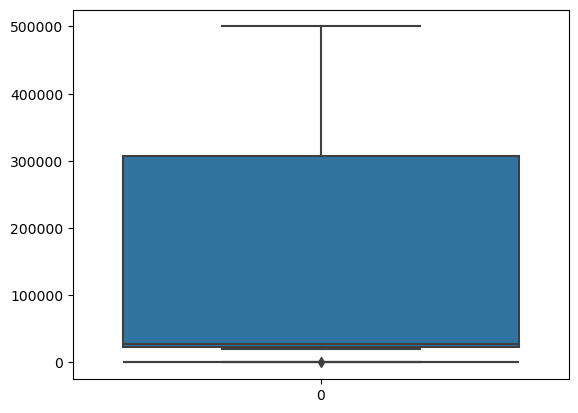

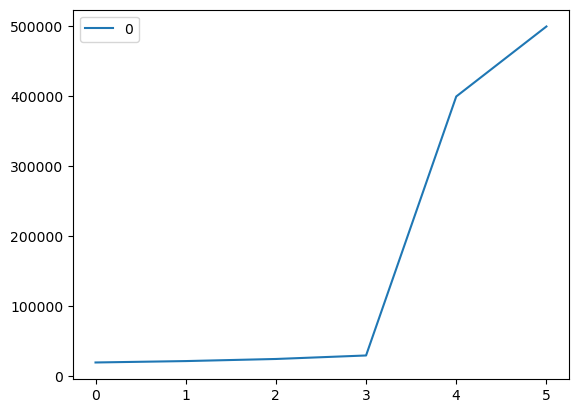

In [ ]:
#to find outliers, box plot can be used from seaborn

stu_hr=[4,5,6,7,8,50]
sns.boxplot(data=stu_hr)

inc=pd.DataFrame([20000,22000,25000,30000,400000,500000])
sns.boxplot(inc)
inc.plot(kind='line')


In [35]:
np.log1p([20000,22000,25000,30000,400000,500000])

array([ 9.90353755,  9.99884319, 10.1266711 , 10.30898599, 12.89922233,
       13.12236538])

c:\Users\vasun\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: ylabel='Count'>

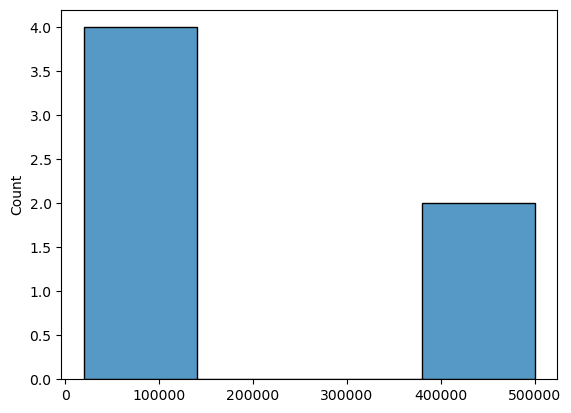

In [ ]:
# to find skewness of the data, hist is used

sns.histplot([20000,22000,25000,30000,400000,500000])

In [43]:
inc.skew()

0    1.054487
dtype: float64

In [44]:
pd.DataFrame(np.log1p([20000,22000,25000,30000,400000,500000])).skew()

0    0.943307
dtype: float64

<Axes: >

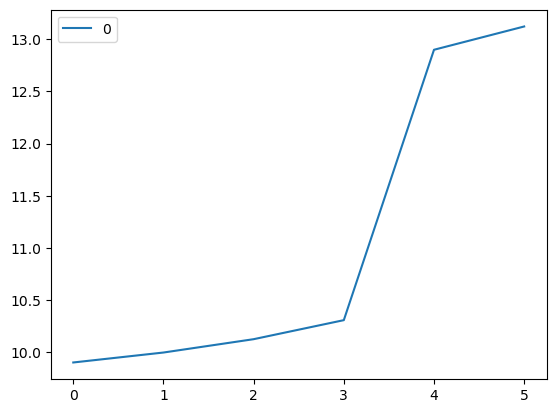

In [ ]:
pd.DataFrame(np.log1p([20000,22000,25000,30000,400000,500000])).plot(kind="line")
